# Section 1: Raw House 1 inspection and cleaning

Goal: take the raw REFIT House 1 files, inspect them, clean them to a regular 1-minute grid, and document every decision.

All thresholds live in `config.yaml`. All cleaning functions live in `src/cleaning.py` and `src/stuck.py` (unit-tested in `tests/`).
Every number in this notebook is printed by the code below. Nothing is typed in by hand.

Reading order: load, inspect, run the pipeline, look at stuck windows and outages, before/after plot, summary.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from src.cleaning import (
    standardise_columns, parse_timestamps, timestamp_report,
    value_report, run_cleaning_pipeline, outage_table,
)

cfg = yaml.safe_load(open(ROOT / "config.yaml"))
C = cfg["cleaning"]
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
print("cleaning settings:", C)

project root: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm
cleaning settings: {'dedup_keep': 'first', 'resample_rule': '1min', 'resample_agg': 'mean', 'max_fill_minutes': 3, 'aggregate_max_w': 23999, 'appliance_max_w': 4000, 'stuck_min_minutes': 30, 'stuck_min_readings': 20, 'gap_thresholds_s': [30, 60, 120, 600, 3600], 'raw_time_zone': 'Europe/London'}


## 1. Load the raw files

House 1 comes as two raw files (Part 1 and Part 2). We load both and add a `part` column.

In [2]:
parts = []
for i, f in enumerate(cfg["paths"]["raw_house1_files"], start=1):
    d = standardise_columns(pd.read_csv(ROOT / f))
    d["part"] = i
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)
del parts

print(f"{len(raw):,} rows in total")
print(raw.groupby("part").size().rename("rows"))
raw.head()

8,518,763 rows in total
part
1    4377877
2    4140886
Name: rows, dtype: int64


,time,unix,aggregate,appliance1,appliance2,appliance3,appliance4,appliance5,appliance6,appliance7,appliance8,appliance9,part
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,1
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0,1
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0,1
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,1


## 2. Inspect the raw data (reporting only, nothing is changed)

### 2.1 Timestamps, per part

In [3]:
parsed = parse_timestamps(raw)
reports = {f"part{p}": timestamp_report(g, C["gap_thresholds_s"]) for p, g in parsed.groupby("part")}
pd.DataFrame(reports)

,part1,part2
n_rows,4377877,4140886
n_unparseable_timestamps,0,0
first_timestamp,2013-10-09 14:06:17,2014-06-27 21:57:50
last_timestamp,2014-10-01 01:27:07,2015-07-10 11:56:32
is_sorted_ascending,False,True
n_out_of_order_steps,2,0
n_duplicate_timestamps,645514,0
n_fully_duplicated_rows,595935,0
step_seconds_quantiles,"{0.01: 1.0, 0.25: 2.0, 0.5: 5.0, 0.75: 13.0, 0...","{0.01: 6.0, 0.25: 7.0, 0.5: 7.0, 0.75: 7.0, 0...."
step_seconds_max,3594413.0,747252.0


### 2.2 Sampling interval (Part 1, unique timestamps only)

count    3732362.00
mean           8.25
std         1875.11
min            1.00
25%            2.00
50%            5.00
75%           13.00
max      3594413.00
Name: time, dtype: float64


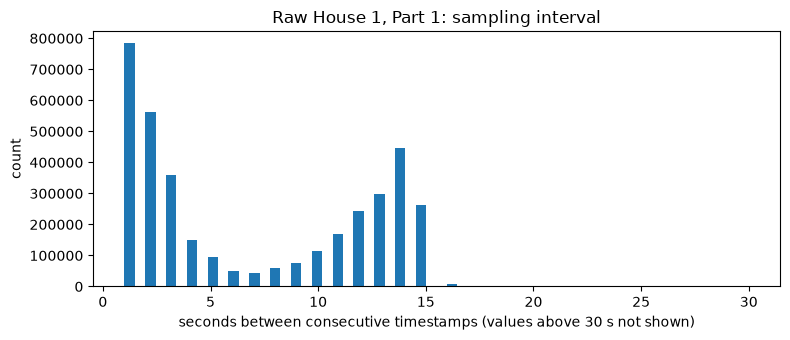

In [4]:
t = parsed.loc[parsed["part"] == 1, "time"].drop_duplicates().sort_values()
step = t.diff().dt.total_seconds().dropna()
print(step.describe().round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
step[step <= 30].plot.hist(bins=60, ax=ax)
ax.set_xlabel("seconds between consecutive timestamps (values above 30 s not shown)")
ax.set_ylabel("count")
ax.set_title("Raw House 1, Part 1: sampling interval")
plt.tight_layout()
plt.show()

### 2.3 Values per channel (negatives, above the sensor limit, zeros)

In [5]:
value_report(parsed, C["aggregate_max_w"], C["appliance_max_w"]).round(2)

,n_missing,pct_missing,n_negative,n_above_limit,limit_w,min,median,mean,max,pct_zero
column,,,,,,,,,,
aggregate,188973,2.22,0,66,23999,0.0,238.0,466.53,29159.0,0.00
appliance1,437890,5.14,0,846,4000,0.0,0.0,19.25,76677.0,72.13
appliance2,459468,5.39,0,40,4000,0.0,0.0,17.21,98301.0,60.88
appliance3,311961,3.66,0,118,4000,0.0,0.0,29.62,73725.0,57.14
appliance4,510963,6.00,0,2085,4000,0.0,0.0,5.26,98301.0,93.58
appliance5,497223,5.84,0,221,4000,0.0,0.0,10.83,73725.0,92.08
appliance6,342337,4.02,0,36,4000,0.0,0.0,11.07,37610.0,95.09
appliance7,232752,2.73,0,374,4000,0.0,0.0,2.89,98299.0,86.84
appliance8,390705,4.59,0,179,4000,0.0,0.0,6.39,98301.0,77.35


### 2.4 Readings above the aggregate limit

`aggregate_max_w` is our own choice (see `config.yaml`). We look at what is actually above it.

In [6]:
agg_hi = parsed.loc[parsed["aggregate"] > C["aggregate_max_w"], ["time", "aggregate", "part"]]
print("raw readings above the aggregate limit:", len(agg_hi))
print()
print(agg_hi["aggregate"].value_counts().sort_index())
print()
print("days with such readings:")
print(agg_hi["time"].dt.date.value_counts().sort_index())

raw readings above the aggregate limit: 66

aggregate
24000.0    62
24732.0     1
28855.0     1
28950.0     1
29159.0     1
Name: count, dtype: int64

days with such readings:
time
2013-11-09     8
2013-12-28    10
2014-07-27    11
2014-10-06     1
2014-10-18     1
2014-10-21     1
2014-10-24     1
2014-12-23     7
2014-12-24    21
2014-12-26     5
Name: count, dtype: int64


### 2.5 Time zone

The raw `Time` column is treated as UK local clock time (Europe/London). This came from checking row counts around the clock changes
(see `outputs/section1_checks*.txt`). The `Unix` column is derived from `Time` in these files, so comparing the two does not reveal the time zone.
The pipeline converts local time to UTC. The repeated hour when clocks go back cannot be placed, so those rows are dropped and counted in the log.

## 3. Run the cleaning pipeline

Steps, in order (all configurable): parse and standardise columns, combine the two parts (Part 1 is primary, Part 2 only after the last Part 1 timestamp), convert local time to UTC, sort and remove duplicate timestamps (keep first), set impossible values to NaN, set stuck-aggregate windows to NaN, resample to 1 minute (mean), forward-fill gaps of up to 3 minutes, flag longer aggregate gaps as outages.

In [7]:
clean, log = run_cleaning_pipeline(raw, cfg)
print(json.dumps(log, indent=2, default=str))

{
  "combine_parts": {
    "primary_part": 1,
    "primary_last_time": "2014-10-01 01:27:07",
    "rows_part1_kept": 4377877,
    "rows_part2_in": 4140886,
    "rows_part2_kept": 3195483,
    "rows_part2_dropped_overlap_or_bad_time": 945403
  },
  "local_to_utc": {
    "assumed_time_zone": "Europe/London",
    "rows_dropped_ambiguous_or_nonexistent": 2185
  },
  "sort_dedup": {
    "rows_in": 7571175,
    "rows_dropped_bad_timestamp": 0,
    "duplicate_rows_removed": 645196,
    "dedup_rule": "first",
    "rows_out": 6925979
  },
  "impossible_values_set_to_nan": {
    "aggregate": {
      "negative": 0,
      "above_limit": 56
    },
    "appliance1": {
      "negative": 0,
      "above_limit": 788
    },
    "appliance2": {
      "negative": 0,
      "above_limit": 36
    },
    "appliance3": {
      "negative": 0,
      "above_limit": 117
    },
    "appliance4": {
      "negative": 0,
      "above_limit": 1700
    },
    "appliance5": {
      "negative": 0,
      "above_limit": 199

## 4. Stuck-aggregate windows

A stuck window is a stretch where the aggregate shows exactly the same value for at least `stuck_min_minutes` minutes and `stuck_min_readings` readings (our choice).
A real household load does not stay identical to the watt for tens of minutes, so we treat these as a stale logger and set all channels to NaN inside the window.

In [8]:
s = log.get("stuck_aggregate")
if s:
    stuck_df = pd.DataFrame(s["runs"])
    stuck_df["start"] = pd.to_datetime(stuck_df["start"])
    stuck_df["end"] = pd.to_datetime(stuck_df["end"])
    stuck_df["minutes"] = ((stuck_df["end"] - stuck_df["start"]).dt.total_seconds() / 60).round(1)
    print(s["rule"])
    print("runs:", s["n_runs"], "| rows set to NaN:", s["rows_set_to_nan"], "| minutes inside runs:", s["minutes_inside_runs"])
    display(stuck_df)
else:
    print("stuck rule not active in config.yaml")

aggregate identical for >= 30 min and >= 20 readings
runs: 10 | rows set to NaN: 7546 | minutes inside runs: 1041.6


,value,start,end,n,minutes
0,152.0,2014-10-04 14:27:39,2014-10-04 16:05:49,93,98.2
1,173.0,2014-10-13 08:43:42,2014-10-13 09:32:04,456,48.4
2,182.0,2014-11-01 14:04:05,2014-11-01 15:15:43,75,71.6
3,356.0,2014-12-23 18:11:11,2014-12-23 19:10:58,96,59.8
4,347.0,2015-01-31 21:00:52,2015-01-31 21:48:15,357,47.4
5,12505.0,2015-02-08 13:24:00,2015-02-08 16:12:32,1533,168.5
6,283.0,2015-02-14 08:06:29,2015-02-14 09:18:33,591,72.1
7,265.0,2015-02-14 15:54:23,2015-02-14 17:22:59,759,88.6
8,167.0,2015-02-18 16:17:38,2015-02-18 21:41:00,3004,323.4
9,377.0,2015-02-25 21:57:13,2015-02-25 23:00:55,515,63.7


## 5. Outages (aggregate still missing after short-gap filling)

number of outages: 459
total outage minutes: 122741

ten longest outages:


,start,end,minutes
287,2014-01-24 01:57:00,2014-03-06 16:22:00,59906.0
434,2015-05-10 22:37:00,2015-05-19 14:09:00,12453.0
444,2015-06-10 12:20:00,2015-06-18 00:38:00,10819.0
381,2014-08-30 11:01:00,2014-09-04 10:32:00,7172.0
427,2015-04-03 00:44:00,2015-04-07 09:17:00,6274.0
424,2015-03-22 08:16:00,2015-03-24 15:22:00,3307.0
436,2015-05-24 09:10:00,2015-05-26 11:08:00,2999.0
401,2014-10-27 00:06:00,2014-10-28 13:45:00,2260.0
426,2015-03-31 03:23:00,2015-04-01 15:25:00,2163.0
421,2015-03-15 10:03:00,2015-03-16 16:15:00,1813.0


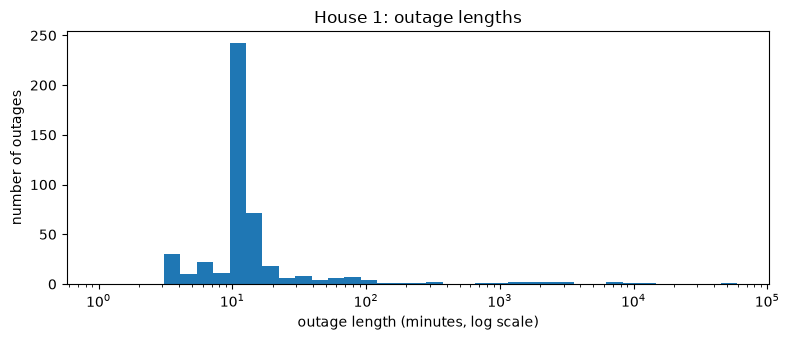

In [9]:
outs = outage_table(clean)
print("number of outages:", len(outs))
print("total outage minutes:", int(outs["minutes"].sum()))
print()
print("ten longest outages:")
display(outs.sort_values("minutes", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(outs["minutes"], bins=np.logspace(0, np.log10(outs["minutes"].max() + 1), 40))
ax.set_xscale("log")
ax.set_xlabel("outage length (minutes, log scale)")
ax.set_ylabel("number of outages")
ax.set_title("House 1: outage lengths")
plt.tight_layout()
plt.show()

## 6. Before and after (aggregate, fridge, washing machine)

We pick a winter day (UK time equals UTC, so raw and cleaned lines line up) with no aggregate outage and no missing values on the three channels,
and where the washing machine was used (cleaned washing-machine power above 100 W at some point). The day is chosen by this rule, not by hand.
Raw readings are grey, the cleaned 1-minute series is blue. The y-axis is limited to the cleaned range, so raw spikes above it are cut off on purpose.

number of candidate days: 50
chosen day: 2013-11-03


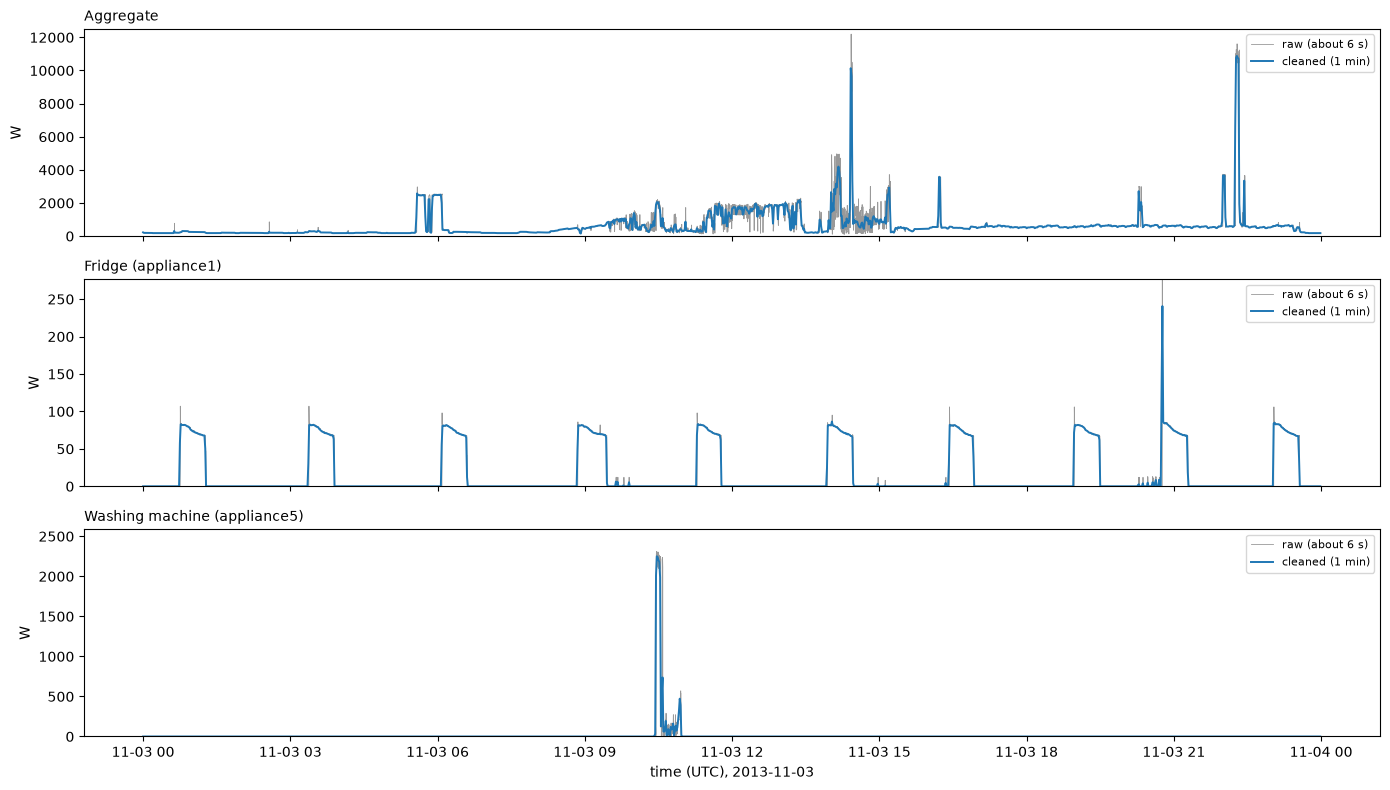

In [10]:
cols = ["aggregate", "appliance1", "appliance5"]
labels = {"aggregate": "Aggregate", "appliance1": "Fridge (appliance1)", "appliance5": "Washing machine (appliance5)"}

day = clean.index.floor("D")
bad = clean[cols].isna().any(axis=1) | clean["agg_outage"]
bad_per_day = bad.groupby(day).sum()
rows_per_day = clean.groupby(day).size()
wm_max = clean["appliance5"].groupby(day).max()

ok = (bad_per_day == 0) & (rows_per_day == 1440) & (wm_max > 100) & bad_per_day.index.month.isin([11, 12, 1, 2, 3])
candidates = list(ok[ok].index)
print("number of candidate days:", len(candidates))
assert candidates, "no day matches the rule, relax it in this cell"

d0 = candidates[0]
d1 = d0 + pd.Timedelta(days=1)
print("chosen day:", d0.date())

c_day = clean.loc[d0:d1 - pd.Timedelta(minutes=1)]
r_day = parsed[(parsed["time"] >= d0) & (parsed["time"] < d1)].drop_duplicates("time").sort_values("time")

fig, axes = plt.subplots(len(cols), 1, figsize=tuple(cfg["plot"]["figsize"][:1] + [8]), sharex=True)
for ax, col in zip(axes, cols):
    ax.plot(r_day["time"], r_day[col], color="0.6", lw=0.6, label="raw (about 6 s)")
    ax.plot(c_day.index, c_day[col], color="tab:blue", lw=1.4, label="cleaned (1 min)")
    ax.set_ylim(0, max(c_day[col].max() * 1.15, 10))
    ax.set_ylabel("W")
    ax.set_title(labels[col], loc="left", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel(f"time (UTC), {d0.date()}")
plt.tight_layout()

fig_dir = ROOT / cfg["paths"]["figures_dir"]
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "section1_before_after.png", dpi=cfg["plot"]["dpi"])
plt.show()

## 7. Summary table (all numbers come from the pipeline log)

In [11]:
summary = {
    "raw rows (both parts)": len(raw),
    "Part 2 rows dropped (overlap with Part 1)": log["combine_parts"].get("rows_part2_dropped_overlap_or_bad_time"),
    "rows dropped, repeated clock hour (DST)": log["local_to_utc"]["rows_dropped_ambiguous_or_nonexistent"],
    "duplicate timestamps removed": log["sort_dedup"]["duplicate_rows_removed"],
    "aggregate readings above limit set to NaN": log["impossible_values_set_to_nan"].get("aggregate", {}).get("above_limit", 0),
    "stuck-aggregate runs": (log.get("stuck_aggregate") or {}).get("n_runs"),
    "minutes in stuck runs": (log.get("stuck_aggregate") or {}).get("minutes_inside_runs"),
    "minutes on the 1-minute grid": log["minutes_total"],
    "minutes forward-filled (aggregate)": log["minutes_aggregate_filled"],
    "minutes in outage (aggregate)": log["minutes_aggregate_outage"],
    "number of outages": log["n_outages"],
}
pd.Series(summary, name="value").to_frame()

,value
raw rows (both parts),8518763.0
Part 2 rows dropped (overlap with Part 1),945403.0
"rows dropped, repeated clock hour (DST)",2185.0
duplicate timestamps removed,645196.0
aggregate readings above limit set to NaN,56.0
stuck-aggregate runs,10.0
minutes in stuck runs,1041.6
minutes on the 1-minute grid,920031.0
minutes forward-filled (aggregate),594.0
minutes in outage (aggregate),122741.0


## 8. Findings and limits

The numbers are in the tables above. This is what they mean and what we did not verify.

- **Two files, overlapping.** Part 1 is primary. Part 2 is used only after the last Part 1 timestamp, because its clock drifts against Part 1 inside the overlap (our check, see `outputs/`).
- **Time zone.** Raw `Time` behaves like UK local time. We convert to UTC and drop the repeated clock hour (a small loss, logged).
- **Duplicates.** Kept the first row per timestamp. Large differences between duplicate rows are rare glitch values.
- **Impossible values.** Appliance readings above 4000 W are set to NaN (REFIT README). Aggregate readings above 23999 W are set to NaN. Most of them are exactly 24000 W in short bursts, which looks like a ceiling value. That is our reading, not a verified fact, and the effect is tiny.
- **Stuck windows.** Aggregate frozen at one value for 30 minutes or more is set to NaN on all channels. The window with 12505 W also freezes the washing-machine channel at a constant value, which suggests a stale logger (inference). The official CLEAN House 1 file contains the same artifact, so CLEAN is not ground truth.
- **Appliance NaN.** In Part 2, NaN in an appliance channel often follows 0 W readings and may mean "unchanged reading". We keep gaps longer than 3 minutes as NaN. Sections 2 and 3 use the official CLEAN files, which are already forward-filled.
- **Outages.** Long aggregate gaps are flagged, not filled. The cause of the many outages of 11 to 13 minutes is not known to us.
- **Not done.** Recovering the dropped repeated hour; confirming stuck windows against another source.